# Лабораторная работа №3 — кластеризация метеорологических наблюдений

**Цель:** изучить методы кластеризации, оценку качества разбиения и интерпретацию выделенных групп на наборе *Rain in Australia*.

В работе используются K-means и агломеративная иерархическая кластеризация. Столбец `RainTomorrow` не участвует в построении кластеров: он применяется только как известная внешняя метка для дополнительной проверки результата.

## 1. Введение

Кластеризация позволяет найти естественные группы наблюдений без использования целевой переменной. Для погодных данных это может быть полезно для выделения типичных состояний атмосферы: сухих, влажных, облачных и ветреных дней. В ходе работы выполняются дескриптивный анализ, очистка и стандартизация признаков, подбор числа кластеров, сравнение двух алгоритмов и содержательная интерпретация результатов.

In [36]:
# Выполнить в Google Colab один раз (если пакет ещё не установлен)
!pip -q install kagglehub[pandas-datasets]

In [37]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from kagglehub import KaggleDatasetAdapter
import kagglehub
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score,
                             normalized_mutual_info_score, homogeneity_completeness_v_measure)
from scipy.cluster.hierarchy import dendrogram, linkage

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 100)

## 2. Описание датасета и дескриптивный анализ

Источник: Kaggle, [Weather Dataset Rattle Package](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package/data). Файл `weatherAUS.csv` содержит ежедневные наблюдения на метеостанциях Австралии. Целевая метка исходной задачи классификации — `RainTomorrow` (будет ли дождь на следующий день).

In [38]:
# Загрузка актуальной версии датасета из Kaggle
file_path = 'weatherAUS.csv'
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    'jsphyg/weather-dataset-rattle-package',
    file_path
)
display(df.head())

Using Colab cache for faster access to the 'weather-dataset-rattle-package' dataset.


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


Датасет содержит 145 460 наблюдений и 23 признака. В нём представлены количественные метеорологические показатели, категориальные направления ветра, дата, станция наблюдения и бинарная метка `RainTomorrow`. Для кластеризации целевая метка далее исключается.

In [39]:
# Размерность, типы и пропуски
overview = pd.DataFrame({
    'тип': df.dtypes.astype(str),
    'пропусков': df.isna().sum(),
    'доля пропусков, %': (df.isna().mean() * 100).round(2),
    'уникальных значений': df.nunique()
}).sort_values('доля пропусков, %', ascending=False)
display(overview)

display((df['RainTomorrow'].value_counts(dropna=False, normalize=True) * 100).round(2).rename('%'))

,тип,пропусков,"доля пропусков, %",уникальных значений
Sunshine,float64,69835,48.01,145
Evaporation,float64,62790,43.17,358
Cloud3pm,float64,59358,40.81,10
Cloud9am,float64,55888,38.42,10
Pressure9am,float64,15065,10.36,546
Pressure3pm,float64,15028,10.33,549
WindDir9am,object,10566,7.26,16
WindGustDir,object,10326,7.10,16
WindGustSpeed,float64,10263,7.06,67
Humidity3pm,float64,4507,3.10,101


,%
RainTomorrow,
No,75.84
Yes,21.91
NaN,2.25


Наиболее проблемны признаки `Sunshine`, `Evaporation`, `Cloud3pm` и `Cloud9am`: доля пропусков в них составляет примерно 38–48 %. Внешняя метка несбалансирована: значений «нет дождя» около 75,8 %, «дождь» — около 21,9 %. Это ещё раз подтверждает, что сравнение кластеров с этой меткой является только дополнительной, а не основной оценкой.

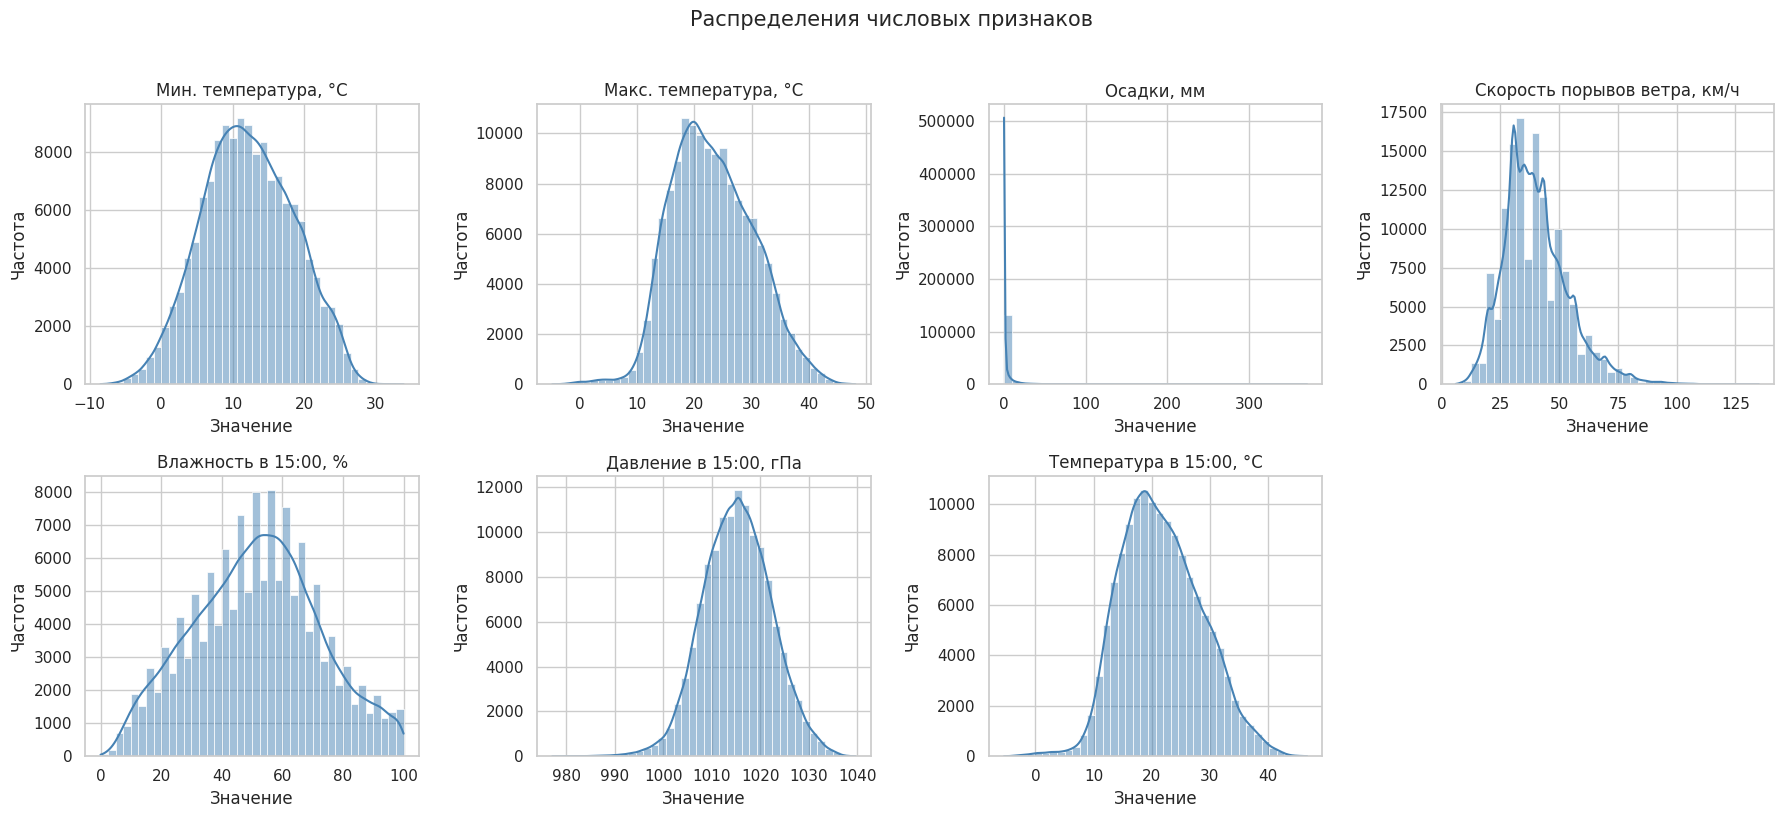

In [40]:
# Русские подписи будут использоваться во всех итоговых графиках
feature_labels = {
    'MinTemp': 'Мин. температура, °C', 'MaxTemp': 'Макс. температура, °C',
    'Rainfall': 'Осадки, мм', 'Evaporation': 'Испарение, мм', 'Sunshine': 'Солнечные часы',
    'WindGustSpeed': 'Скорость порывов ветра, км/ч', 'WindSpeed9am': 'Скорость ветра в 9:00, км/ч',
    'WindSpeed3pm': 'Скорость ветра в 15:00, км/ч', 'Humidity9am': 'Влажность в 9:00, %',
    'Humidity3pm': 'Влажность в 15:00, %', 'Pressure9am': 'Давление в 9:00, гПа',
    'Pressure3pm': 'Давление в 15:00, гПа', 'Cloud9am': 'Облачность в 9:00, октанты',
    'Cloud3pm': 'Облачность в 15:00, октанты', 'Temp9am': 'Температура в 9:00, °C',
    'Temp3pm': 'Температура в 15:00, °C'
}

# Распределения ключевых числовых характеристик
hist_cols = ['MinTemp', 'MaxTemp', 'Rainfall', 'WindGustSpeed', 'Humidity3pm', 'Pressure3pm', 'Temp3pm']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), hist_cols):
    sns.histplot(df[col].dropna(), bins=40, kde=True, ax=ax, color='steelblue')
    ax.set_title(feature_labels[col])
    ax.set_xlabel('Значение')
    ax.set_ylabel('Частота')
for ax in axes.ravel()[len(hist_cols):]:
    ax.remove()
fig.suptitle('Распределения числовых признаков', y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

# По гистограммам можно оценить близость к нормальному распределению.
# Осадки и скорости ветра обычно имеют правую асимметрию, поэтому стандартизация
# применяется после заполнения пропусков, а не предполагает нормальность признаков.

Температура и давление имеют сравнительно одновершинные распределения, тогда как осадки и скорость порывов ветра заметно скошены вправо. Следовательно, предположение о нормальности выполняется не для всех признаков. Это не препятствует применению `StandardScaler`: он выравнивает масштабы, но не требует нормального закона распределения.

,признак,выбросов по IQR,"доля, %"
2,Rainfall,25578,17.58
5,WindGustSpeed,3092,2.13
7,WindSpeed3pm,2523,1.73
3,Evaporation,1995,1.37
6,WindSpeed9am,1817,1.25
8,Humidity9am,1425,0.98
10,Pressure9am,1191,0.82
11,Pressure3pm,919,0.63
15,Temp3pm,764,0.53
1,MaxTemp,489,0.34


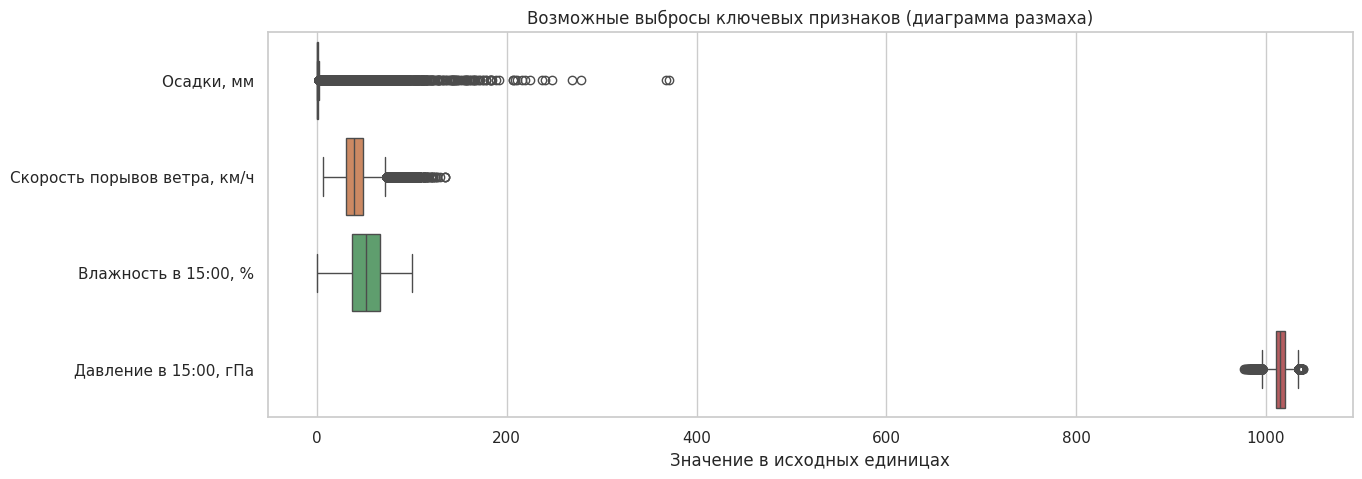

In [41]:
# Анализ выбросов правилом 1.5 IQR для используемых количественных признаков
numeric_cols = ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
                'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm',
                'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm',
                'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']

outlier_rows = []
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    outlier_rows.append([col, int(mask.sum()), round(mask.mean() * 100, 2)])
outliers = pd.DataFrame(outlier_rows, columns=['признак', 'выбросов по IQR', 'доля, %'])
display(outliers.sort_values('доля, %', ascending=False))

plt.figure(figsize=(14, 5))
box_data = df[['Rainfall', 'WindGustSpeed', 'Humidity3pm', 'Pressure3pm']].rename(columns=feature_labels)
sns.boxplot(data=box_data, orient='h')
plt.title('Возможные выбросы ключевых признаков (диаграмма размаха)')
plt.xlabel('Значение в исходных единицах')
plt.show()

# Экстремальные наблюдения сохраняются для дальнейшей содержательной интерпретации.

Правило 1,5 IQR отмечает часть наблюдений с экстремальными осадками и скоростями ветра. Они не удаляются, поскольку для метеорологических данных такие значения могут описывать реальные штормы или ливни, то есть представляют самостоятельный погодный режим, а не обязательно ошибку измерения.

### Проверка применимости кластеризации

В исходном наборе есть класс `RainTomorrow`, однако он исключается из пространства признаков. Поэтому алгоритмы не получают готового разбиения и решают именно задачу обучения без учителя. Кластеризация осмысленна: погодные дни могут различаться температурой, влажностью, давлением, облачностью и ветром. IQR-анализ выше позволяет отделить возможные выбросы от реальных экстремальных погодных ситуаций; их сохраняем для интерпретации.

In [42]:
# Подготовка внешней метки и воспроизводимая выборка для вычислительно затратных методов
# Location намеренно исключён: иначе кластеры в первую очередь отражали бы станции, а не погоду.
categorical_cols = ['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']
model_cols = numeric_cols + categorical_cols
work = df[model_cols + ['RainTomorrow']].copy()
work = work[work['RainTomorrow'].isin(['Yes', 'No'])].copy()
work['RainTomorrow_binary'] = (work['RainTomorrow'] == 'Yes').astype(int)

# 5 000 объектов достаточно для устойчивой оценки, а Ward-иерархия остаётся выполнимой в Colab
n_sample = min(5000, len(work))
sample = (work.groupby('RainTomorrow_binary', group_keys=False)
          .apply(lambda x: x.sample(n=max(1, round(n_sample * len(x) / len(work))),
                                  random_state=RANDOM_STATE))
          .sample(frac=1, random_state=RANDOM_STATE)
          .head(n_sample).reset_index(drop=True))

X_raw = sample[model_cols]
y_external = sample['RainTomorrow_binary'].to_numpy()

Для расчётов использована воспроизводимая стратифицированная выборка из 5 000 объектов; доля дней с дождём завтра в ней составляет 22,4 %. Признак станции (`Location`) исключён, чтобы полученные группы отражали погодные условия, а не различия между географическими пунктами.

## 3. Предобработка данных

Числовые признаки измеряются в разных единицах (°C, мм, км/ч, гПа, проценты), поэтому используется `StandardScaler`: после центрирования каждый числовой признак имеет нулевое среднее и единичное стандартное отклонение. Это необходимо, поскольку K-means и Ward-иерархия основаны на евклидовых расстояниях. Пропуски заполняются медианой для числовых и наиболее частым значением для категориальных признаков. Направления ветра и `RainToday` кодируются one-hot способом.

In [43]:
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_cols),
    ('cat', categorical_pipe, categorical_cols)
])

X = preprocessor.fit_transform(X_raw)
feature_names = preprocessor.get_feature_names_out()

 После заполнения пропусков, стандартизации 16 числовых характеристик и one-hot-кодирования категориальных переменных матрица признаков имеет размер 5 000 × 66. Стандартизированные числовые признаки имеют среднее около нуля и стандартное отклонение около единицы, поэтому ни один из исходных масштабов не доминирует в евклидовом расстоянии.

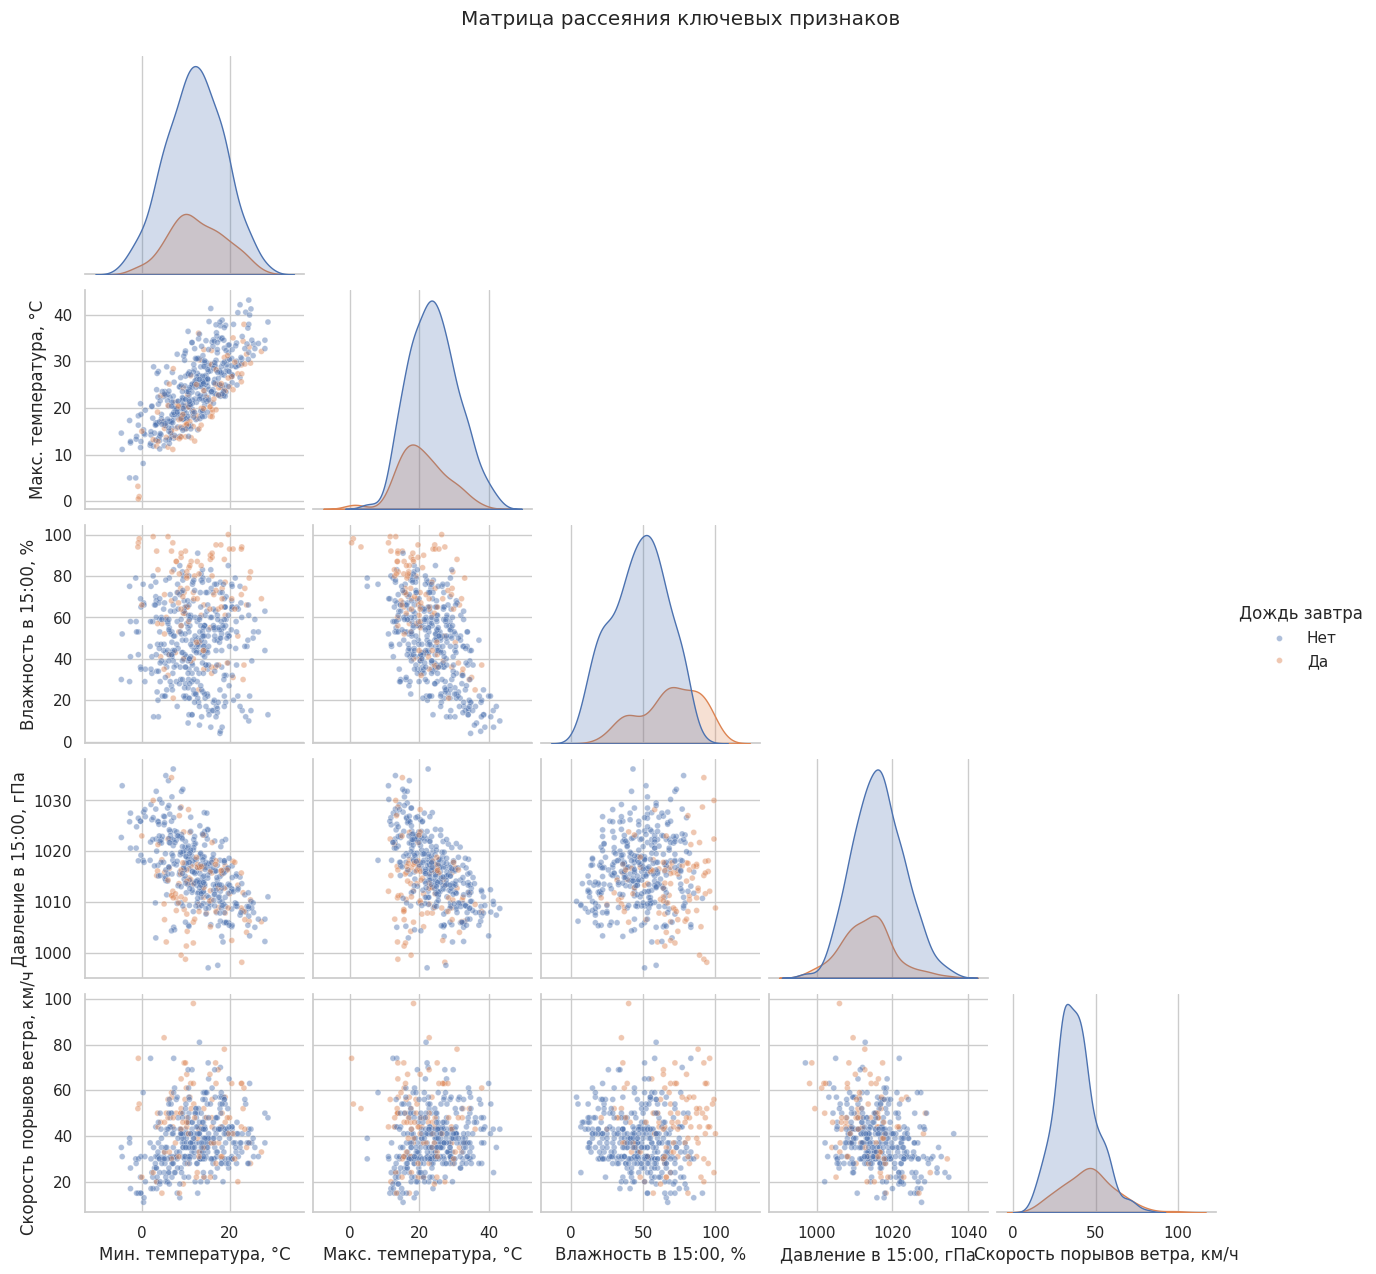

In [44]:
# Матрица диаграмм рассеяния: небольшой поднабор для читабельности
pair_cols = ['MinTemp', 'MaxTemp', 'Humidity3pm', 'Pressure3pm', 'WindGustSpeed']
pair_data = sample[pair_cols + ['RainTomorrow']].sample(min(500, len(sample)), random_state=RANDOM_STATE)
pair_data = pair_data.rename(columns={**feature_labels, 'RainTomorrow': 'Дождь завтра'})
pair_data['Дождь завтра'] = pair_data['Дождь завтра'].map({'Yes': 'Да', 'No': 'Нет'})
pair_vars = [feature_labels[col] for col in pair_cols]
sns.pairplot(pair_data, vars=pair_vars, hue='Дождь завтра', corner=True,
             plot_kws={'alpha': 0.45, 's': 18})
plt.suptitle('Матрица рассеяния ключевых признаков', y=1.02)
plt.show()

# Ожидаем перекрывающиеся, приблизительно выпуклые группы; поэтому K-means и Ward-метод
# подходят для сравнения. DBSCAN менее удобен здесь из-за разной плотности погодных состояний.

Видны ожидаемые связи: минимальная и максимальная температура положительно связаны, а влажность и давление частично разделяют разные состояния погоды. При этом точки двух значений `RainTomorrow` существенно перекрываются. На двумерных проекциях не наблюдается отчётливо отделённых групп сложной формы; поэтому для сравнения выбраны методы k-средних и Ward-иерархия, ориентированные на компактные кластеры.

## 4. Ход работы: подбор числа кластеров и построение моделей

Для K-means число кластеров выбирается одновременно по методу локтя (инерция) и максимальному среднему силуэту. Для иерархической кластеризации строится дендрограмма подвыборки; затем используется то же значение `k`, что даёт прозрачное сравнение методов.

,k,inertia,silhouette
0,2,79260.1256,0.1548
1,3,71558.1580,0.1398
2,4,67815.2072,0.0885
3,5,64562.7546,0.0935
4,6,61848.5636,0.0975
5,7,59842.0610,0.0908
6,8,58304.1553,0.0831


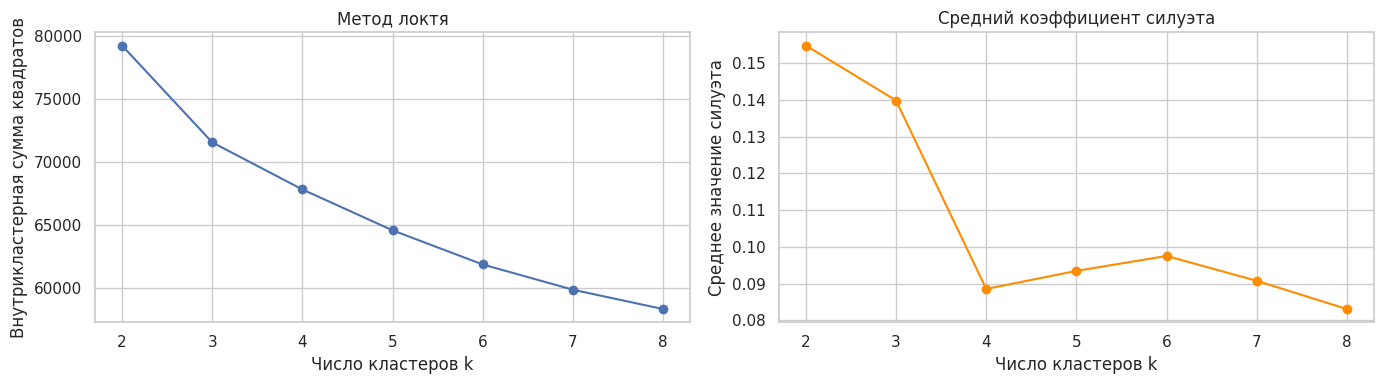

In [45]:
# Метод локтя и силуэтный анализ
k_values = range(2, 9)
inertias, silhouettes = [], []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X, labels, sample_size=min(3000, len(X)), random_state=RANDOM_STATE))

selection = pd.DataFrame({'k': list(k_values), 'inertia': inertias, 'silhouette': silhouettes})
display(selection.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(k_values, inertias, marker='o')
axes[0].set(title='Метод локтя', xlabel='Число кластеров k', ylabel='Внутрикластерная сумма квадратов')
axes[1].plot(k_values, silhouettes, marker='o', color='darkorange')
axes[1].set(title='Средний коэффициент силуэта', xlabel='Число кластеров k', ylabel='Среднее значение силуэта')
plt.tight_layout()
plt.show()

best_k = int(selection.loc[selection['silhouette'].idxmax(), 'k'])

 Инерция убывает при увеличении числа кластеров, как и должно быть, но после `k=2` её снижение не даёт более качественного разделения. Максимальный средний коэффициент силуэта равен 0,155 при `k=2`; для `k=3` он снижается до 0,140, а для бо́льших `k` находится в диапазоне 0,083–0,098. Поэтому для обоих методов выбрано два кластера. Невысокое абсолютное значение силуэта заранее указывает на перекрытие групп.

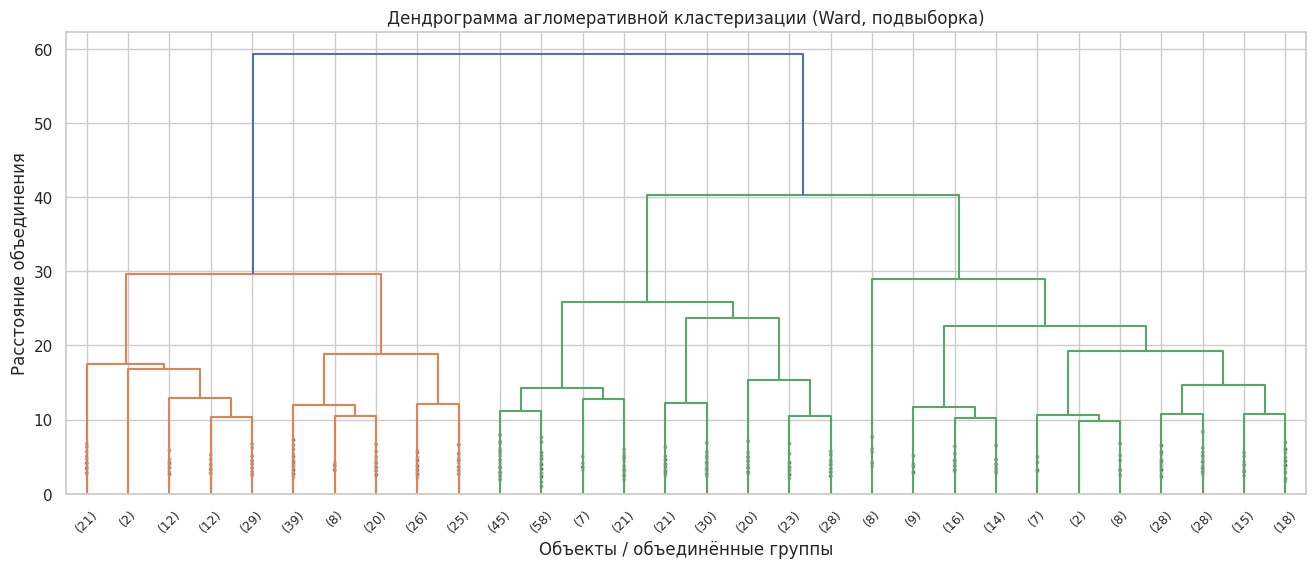

In [46]:
# Дендрограмма Ward-иерархии на подвыборке: полный график для 5000 точек был бы нечитаем
dendro_n = min(600, len(X))
rng = np.random.default_rng(RANDOM_STATE)
dendro_idx = rng.choice(len(X), size=dendro_n, replace=False)
Z = linkage(X[dendro_idx], method='ward')
plt.figure(figsize=(16, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=45, leaf_font_size=9,
           show_contracted=True)
plt.title('Дендрограмма агломеративной кластеризации (Ward, подвыборка)')
plt.xlabel('Объекты / объединённые группы')
plt.ylabel('Расстояние объединения')
plt.show()

На дендрограмме заметен крупный уровень объединения двух основных ветвей. Разрез перед этим объединением соответствует двум укрупнённым погодным режимам и согласуется с выбором `k=2` по среднему коэффициенту силуэта. Более глубокие разрезы давали бы меньшие, но менее устойчивые подгруппы.

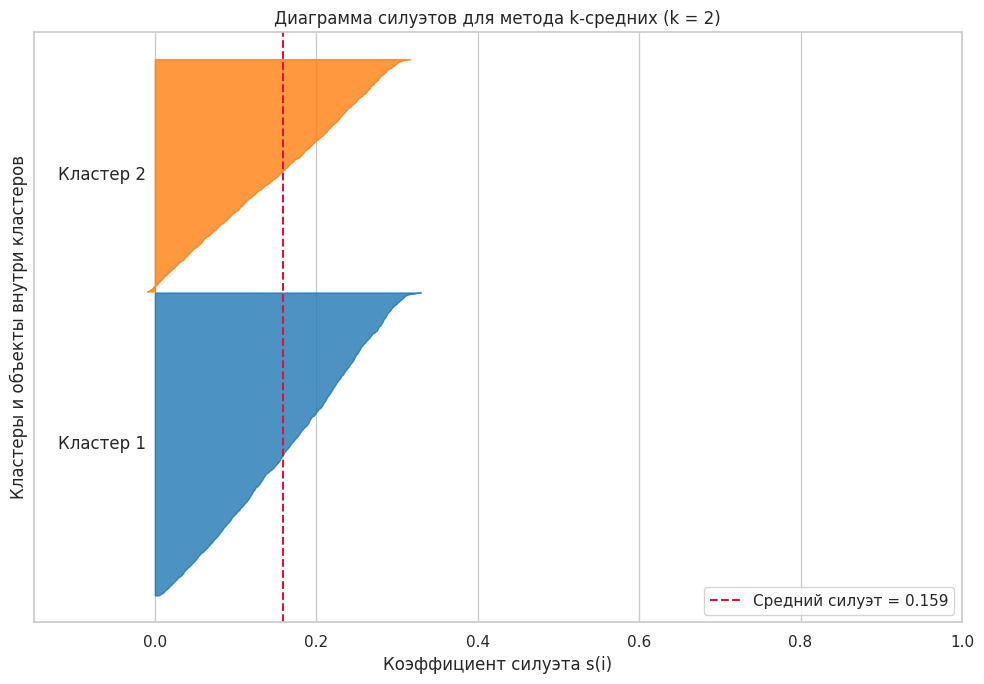

In [47]:
# Полная диаграмма силуэтов для выбранного разбиения K-means
# В отличие от предыдущего графика, здесь видны силуэты отдельных объектов внутри каждого кластера.
silhouette_model = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
silhouette_labels = silhouette_model.fit_predict(X)
silhouette_values = silhouette_samples(X, silhouette_labels)
mean_silhouette = silhouette_values.mean()

fig, ax = plt.subplots(figsize=(10, 7))
y_lower = 10
for cluster_id in range(best_k):
    cluster_values = np.sort(silhouette_values[silhouette_labels == cluster_id])
    cluster_size = len(cluster_values)
    y_upper = y_lower + cluster_size
    color = plt.cm.tab10(cluster_id % 10)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_values,
                     facecolor=color, edgecolor=color, alpha=0.8)
    ax.text(-0.12, y_lower + cluster_size / 2, f'Кластер {cluster_id + 1}', va='center')
    y_lower = y_upper + 10

ax.axvline(mean_silhouette, color='crimson', linestyle='--', linewidth=1.5,
           label=f'Средний силуэт = {mean_silhouette:.3f}')
ax.set_title(f'Диаграмма силуэтов для метода k-средних (k = {best_k})')
ax.set_xlabel('Коэффициент силуэта s(i)')
ax.set_ylabel('Кластеры и объекты внутри кластеров')
ax.set_yticks([])
ax.set_xlim(min(-0.15, silhouette_values.min() - 0.03), 1.0)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

 Большая часть коэффициентов силуэта положительна, поэтому объекты в среднем ближе к своему кластеру, чем к соседнему. Однако распределение сосредоточено недалеко от нуля, а среднее значение равно 0,155. Это подтверждает, что разбиение на два кластера является лучшим среди проверенных вариантов, но граница между погодными режимами размыта; отрицательные значения соответствуют пограничным наблюдениям.

In [48]:
# Два метода кластеризации с выбранным числом групп
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
labels_kmeans = kmeans.fit_predict(X)

hierarchical = AgglomerativeClustering(n_clusters=best_k, linkage='ward')
labels_hierarchical = hierarchical.fit_predict(X)

 Метод k-средних сформировал кластеры размером 2 830 и 2 170 объектов, то есть достаточно сбалансированные. Ward-иерархия получила группы из 3 277 и 1 723 объектов. Сильная асимметрия размеров у Ward может быть признаком того, что этот метод объединяет часть переходных наблюдений в более крупный кластер.

In [49]:
# Внутренние, внешние и геометрические показатели качества
def geometry_metrics(data, labels):
    centers = np.vstack([data[labels == c].mean(axis=0) for c in np.unique(labels)])
    own_centers = np.vstack([centers[c] for c in labels])
    compactness = np.linalg.norm(data - own_centers, axis=1).mean()
    distances = np.linalg.norm(centers[:, None, :] - centers[None, :, :], axis=2)
    min_between = distances[np.triu_indices_from(distances, k=1)].min()
    return compactness, min_between, centers

def evaluate(name, labels):
    compactness, min_between, centers = geometry_metrics(X, labels)
    h, c, v = homogeneity_completeness_v_measure(y_external, labels)
    return {
        'метод': name,
        'Коэффициент силуэта ↑': silhouette_score(X, labels, sample_size=min(3000, len(X)), random_state=RANDOM_STATE),
        'Индекс Калински—Харабаша ↑': calinski_harabasz_score(X, labels),
        'Индекс Дэвиса—Боулдина ↓': davies_bouldin_score(X, labels),
        'Компактность ↓': compactness,
        'Мин. расстояние центров ↑': min_between,
        'Скорректированный индекс Рэнда ↑': adjusted_rand_score(y_external, labels),
        'Нормализованная взаимная информация ↑': normalized_mutual_info_score(y_external, labels),
        'V-мера (внешняя) ↑': v
    }, centers

row_kmeans, centers_kmeans = evaluate('K-means', labels_kmeans)
row_hier, centers_hier = evaluate('Иерархическая Ward', labels_hierarchical)
metrics_table = pd.DataFrame([row_kmeans, row_hier]).set_index('метод')
display(metrics_table.round(3))

,Коэффициент силуэта ↑,Индекс Калински—Харабаша ↑,Индекс Дэвиса—Боулдина ↓,Компактность ↓,Мин. расстояние центров ↑,Скорректированный индекс Рэнда ↑,Нормализованная взаимная информация ↑,V-мера (внешняя) ↑
метод,,,,,,,,
K-means,0.155,1038.996,2.077,3.799,3.663,-0.004,0.016,0.016
Иерархическая Ward,0.125,736.111,2.363,3.893,3.299,-0.014,0.003,0.003


K-means превосходит Ward по внутренним показателям: силуэт 0,155 против 0,125, индекс Калински—Харабаша 1 039 против 736, индекс Дэвиса—Боулдина 2,077 против 2,363. Он также немного компактнее (3,799 против 3,893) и имеет более удалённые центры (3,663 против 3,299). Внешние метрики близки к нулю: для K-means скорректированный индекс Рэнда равен -0,004, а нормализованная взаимная информация — 0,016. Следовательно, выделенные кластеры не воспроизводят бинарную метку дождя завтра, но это ожидаемо для несупервизорной задачи.

In [50]:
# Информационная значимость исходных признаков относительно известной RainTomorrow
# Это диагностический, а не кластерный расчёт: целевая метка не использовалась для обучения.
mi = mutual_info_classif(X, y_external, random_state=RANDOM_STATE)
mi_table = (pd.DataFrame({'преобразованный признак': feature_names, 'MI с RainTomorrow': mi})
            .sort_values('MI с RainTomorrow', ascending=False))
display(mi_table.head(15).round(4))

# Наиболее информативные показатели (часто влажность, облачность, давление) полезны также
# для интерпретации найденных метеорологических групп.

,преобразованный признак,MI с RainTomorrow
9,num__Humidity3pm,0.1264
4,num__Sunshine,0.0684
13,num__Cloud3pm,0.0520
65,cat__RainToday_Yes,0.0473
2,num__Rainfall,0.0466
64,cat__RainToday_No,0.0447
8,num__Humidity9am,0.0436
12,num__Cloud9am,0.0399
5,num__WindGustSpeed,0.0280
11,num__Pressure3pm,0.0271


Наиболее заметную взаимную информацию с фактом дождя завтра имеет влажность в 15:00 (≈0,126). За ней следуют продолжительность солнечного сияния, облачность в 15:00, наличие дождя сегодня и количество осадков. Эти признаки содержательно обоснованно включены в анализ: они описывают различие между влажными и сухими погодными режимами.

### Влияние параметра K-means

Ниже исследуется влияние `k` на качество. При росте `k` инерция всегда уменьшается, поэтому решение нельзя принимать только по ней: учитывается силуэт и интерпретируемость групп.

,k,Внутрикластерная сумма квадратов,Средний коэффициент силуэта,Индекс Калински—Харабаша
0,2,79260.126,0.155,1038.996
1,3,71558.158,0.140,844.218
2,4,67815.207,0.089,685.671
3,5,64562.755,0.093,602.959
4,6,61848.564,0.098,547.267
5,7,59842.061,0.091,499.155
6,8,58304.155,0.083,457.856


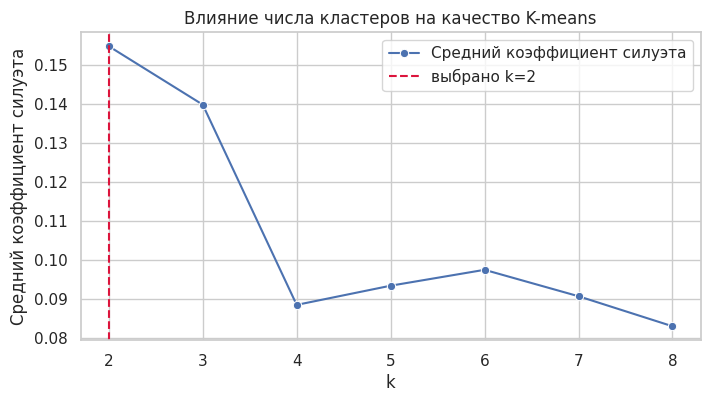

In [51]:
param_effect = selection.rename(columns={'inertia': 'Внутрикластерная сумма квадратов',
                                        'silhouette': 'Средний коэффициент силуэта'}).copy()
param_effect['Индекс Калински—Харабаша'] = [
    calinski_harabasz_score(X, KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X))
    for k in k_values
]
display(param_effect.round(3))

plt.figure(figsize=(8, 4))
sns.lineplot(data=param_effect, x='k', y='Средний коэффициент силуэта', marker='o',
             label='Средний коэффициент силуэта')
plt.axvline(best_k, color='crimson', linestyle='--', label=f'выбрано k={best_k}')
plt.title('Влияние числа кластеров на качество K-means')
plt.legend()
plt.show()

При увеличении `k` внутрикластерная сумма квадратов монотонно уменьшается: это техническое свойство K-means, а не доказательство улучшения качества. Напротив, максимальные значения и коэффициента силуэта, и индекса Калински—Харабаша достигаются при `k=2`, затем оба показателя снижаются. Таким образом, усложнение модели дополнительными кластерами не оправдано.

## 5. Визуализация результатов и интерпретация

PCA проецирует многомерное пространство в две главные компоненты. Проекция служит для визуального анализа и не заменяет метрики, рассчитанные в полном пространстве признаков.

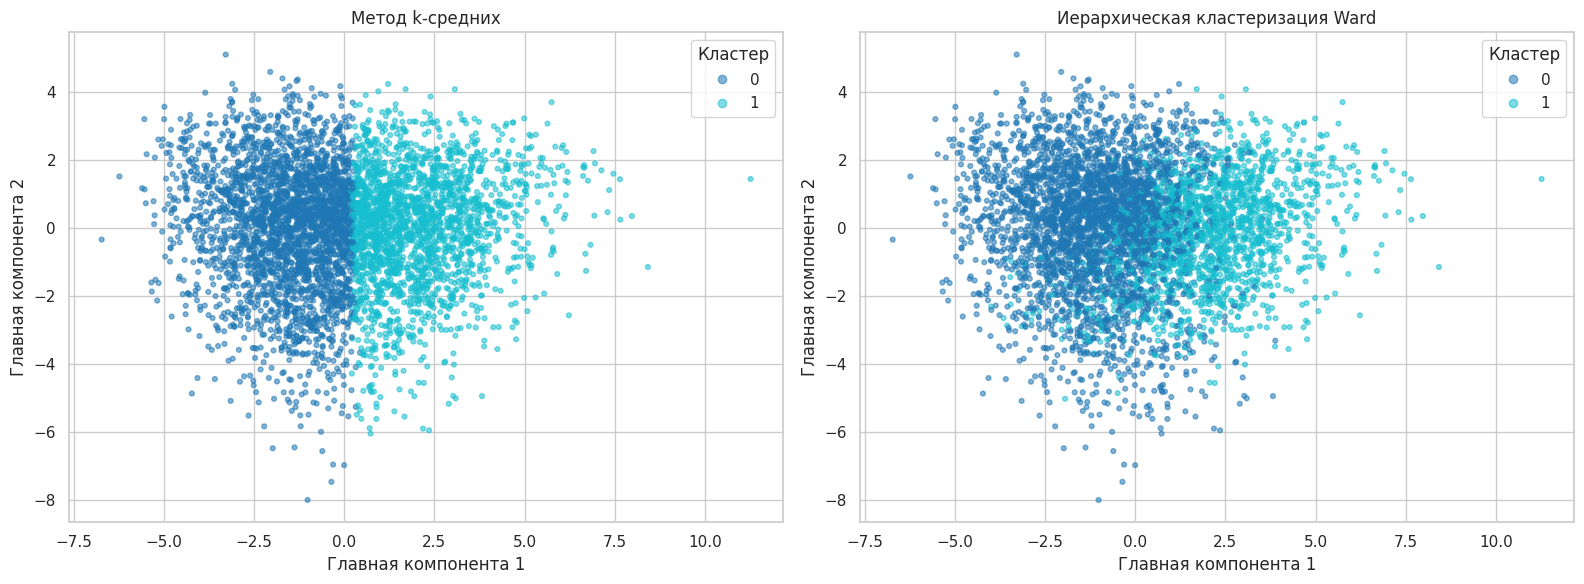

Ward,0,1
Метод k-средних,,
0,0.93,0.07
1,0.30,0.70


In [52]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, labels, title in zip(axes, [labels_kmeans, labels_hierarchical],
                            ['Метод k-средних', 'Иерархическая кластеризация Ward']):
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='tab10', s=12, alpha=0.55)
    ax.set(title=title, xlabel='Главная компонента 1', ylabel='Главная компонента 2')
    ax.legend(*scatter.legend_elements(), title='Кластер', loc='best')
plt.tight_layout()
plt.show()

comparison = pd.crosstab(labels_kmeans, labels_hierarchical, normalize='index').round(2)
comparison.index.name, comparison.columns.name = 'Метод k-средних', 'Ward'
display(comparison)

 Первые две главные компоненты объясняют 42,8 % дисперсии, поэтому проекция отражает общую структуру, но не все различия исходного 66-мерного пространства. На графиках оба метода выделяют похожие два крупных облака с переходной зоной между ними. Таблица соответствия показывает, что разбиения частично согласуются, хотя Ward относит больше наблюдений к одному кластеру; это соответствует сравнению размеров кластеров и метрик.

,"Мин. температура, °C","Макс. температура, °C","Осадки, мм",Солнечные часы,"Скорость порывов ветра, км/ч","Влажность в 15:00, %","Давление в 15:00, гПа","Температура в 15:00, °C","Доля «дождь завтра», %"
cluster,,,,,,,,,
0,8.87,18.52,3.20,5.97,37.76,58.76,1018.34,17.21,27.42
1,16.57,29.41,1.37,9.51,43.18,41.87,1011.62,27.60,15.90


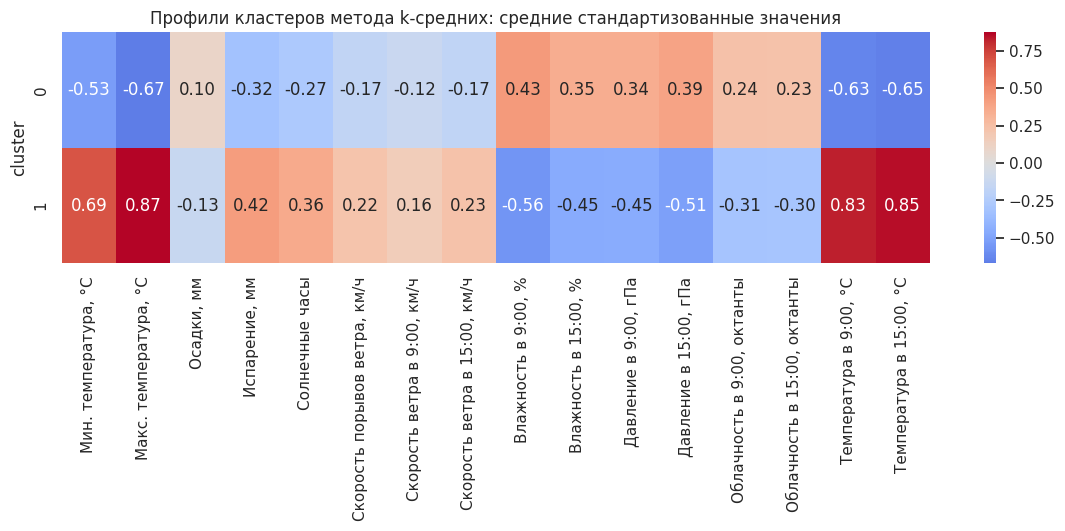

In [53]:
# Профили кластеров в исходных единицах: средние числовые значения
profile_kmeans = sample[numeric_cols].copy()
profile_kmeans['cluster'] = labels_kmeans
profile_kmeans['RainTomorrow=Yes, %'] = y_external * 100
profile_kmeans = profile_kmeans.groupby('cluster').mean()

profile_to_show = profile_kmeans[['MinTemp', 'MaxTemp', 'Rainfall', 'Sunshine', 'WindGustSpeed',
                                  'Humidity3pm', 'Pressure3pm', 'Temp3pm', 'RainTomorrow=Yes, %']].copy()
profile_to_show = profile_to_show.rename(columns={**feature_labels, 'RainTomorrow=Yes, %': 'Доля «дождь завтра», %'})
display(profile_to_show.round(2))

# Тепловая карта стандартизованных средних: удобно видеть профиль каждого кластера
cluster_standardized = pd.DataFrame(X[:, :len(numeric_cols)], columns=[feature_labels[c] for c in numeric_cols])
cluster_standardized['cluster'] = labels_kmeans
plt.figure(figsize=(14, max(3, best_k * 0.8)))
sns.heatmap(cluster_standardized.groupby('cluster').mean(), center=0, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('Профили кластеров метода k-средних: средние стандартизованные значения')
plt.show()

Кластер 1 более прохладный и влажный: средняя температура в 15:00 составляет 17,21 °C, влажность — 58,76 %, а солнечное сияние — 5,97 часа. Кластер 2 теплее и суше: 27,60 °C, 41,87 % и 9,51 часа соответственно. Доля дождливого следующего дня выше в первом кластере (27,42 % против 15,90 %), что согласуется с его влажным профилем. Следовательно, выделенные группы разумно интерпретировать как «прохладный/влажный» и «тёплый/сухой» режимы.

## 6. Заключение

В выполненном запуске оптимальным оказалось `k = 2`. Метод k-средних дал средний коэффициент силуэта около 0,155, а иерархический метод Ward — около 0,125; также у метода k-средних выше индекс Калински-Харабаша и ниже индекс Дэвиса-Боулдина. Следовательно, из двух проверенных методов предпочтителен K-means. Однако значения силуэта ниже 0,25 указывают на слабую естественную разделимость: погодные режимы в данных заметно перекрываются, поэтому кластеры не следует трактовать как строго изолированные классы.

Внешние показатели близки к нулю (скорректированный индекс Рэнда около -0,004 и нормализованная взаимная информация около 0,016). Это не является точностью классификатора: кластер описывает метеорологический режим, а дождь завтра - только один из его возможных исходов. По профилям метода k-средних первая группа характеризуется более прохладной и влажной погодой, вторая - более тёплой, солнечной и сухой. Таким образом, кластеризация применима для разведочного анализа погодных данных и выделения типичных состояний атмосферы, но не заменяет классификацию `RainTomorrow`.